# CHMENG 250 — Homework 2 Computational Component
## Completed working notebook: Vector Fields, Gradients, and Curl in 2D

This notebook completes the TODO code and provides explanations. The pasted Markdown lost some displayed math and the numerical error-reduction factor in Part 4c; the calculations below follow the supplied code and stated second-order central differences.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

## Setup

In [2]:
L = 2.0
U0 = 1.0
N = 101
x = np.linspace(-L, L, N)
y = np.linspace(-L, L, N)
X, Y = np.meshgrid(x, y)
dx = x[1] - x[0]
dy = y[1] - y[0]

## Part 1 — Taylor–Green velocity field and streamlines

$$u=U_0\sin(\pi x/L)\cos(\pi y/L),\qquad v=-U_0\cos(\pi x/L)\sin(\pi y/L).$$

Analytically,
$$\frac{\partial u}{\partial x}=\frac{\pi U_0}{L}\cos(\pi x/L)\cos(\pi y/L),\quad
\frac{\partial v}{\partial y}=-\frac{\pi U_0}{L}\cos(\pi x/L)\cos(\pi y/L).$$
The divergence is identically zero.

In [3]:
u = U0 * np.sin(np.pi * X / L) * np.cos(np.pi * Y / L)
v = -U0 * np.cos(np.pi * X / L) * np.sin(np.pi * Y / L)
dudx = U0 * (np.pi / L) * np.cos(np.pi * X / L) * np.cos(np.pi * Y / L)
dvdy = -U0 * (np.pi / L) * np.cos(np.pi * X / L) * np.cos(np.pi * Y / L)
div = dudx + dvdy
print(f"Max |div(u)|: {np.max(np.abs(div)):.2e}")

Max |div(u)|: 0.00e+00


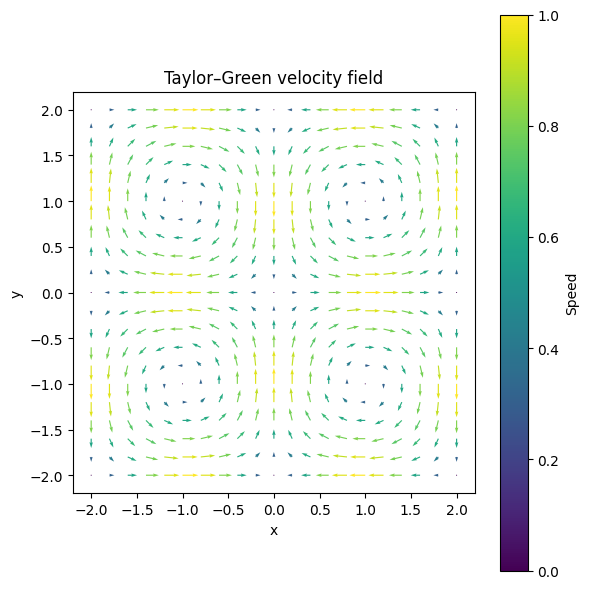

In [4]:
s = 5
fig, ax = plt.subplots(figsize=(6, 6))
speed = np.sqrt(u**2 + v**2)
q = ax.quiver(X[::s, ::s], Y[::s, ::s], u[::s, ::s], v[::s, ::s], speed[::s, ::s], cmap='viridis')
fig.colorbar(q, ax=ax, label='Speed')
ax.set_aspect('equal')
ax.set_title('Taylor–Green velocity field')
ax.set_xlabel('x'); ax.set_ylabel('y')
plt.tight_layout()
plt.show()

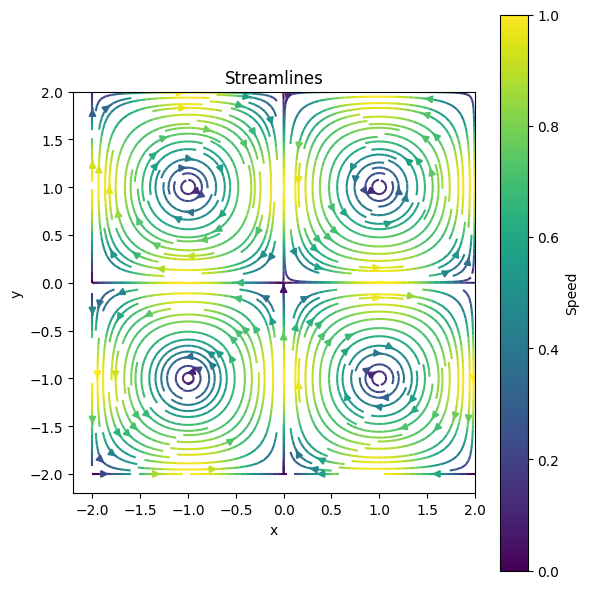

In [5]:
fig, ax = plt.subplots(figsize=(6, 6))
strm = ax.streamplot(x, y, u, v, color=speed, density=2, cmap='viridis')
fig.colorbar(strm.lines, ax=ax, label='Speed')
ax.set_aspect('equal')
ax.set_title('Streamlines')
ax.set_xlabel('x'); ax.set_ylabel('y')
plt.tight_layout()
plt.show()

**Written answer — stagnation points and vortex cells.** The stagnation points satisfy $u=v=0$. Inside the displayed domain $[-L,L]^2$, they include points $(x,y)=(mL,nL)$ and $(x,y)=((m+\tfrac12)L,(n+\tfrac12)L)$ wherever they fall on the domain, for integers $m,n$. The second family gives the **four vortex-cell centres** $(\pm L/2,\pm L/2)$. The first family gives the corner/intersection stagnation points (the interior origin is a saddle). The displayed domain contains **four complete vortex cells**. Boundary stagnation points also occur where the specified formula vanishes.

## Part 2 — Vorticity

$$\omega_z=\frac{\partial v}{\partial x}-\frac{\partial u}{\partial y}=\frac{2\pi U_0}{L}\sin(\pi x/L)\sin(\pi y/L).$$
Central differences: $(f_{i+1}-f_{i-1})/(2\Delta)$, evaluated only at interior points.

In [6]:
omega_exact = 2 * U0 * (np.pi / L) * np.sin(np.pi * X / L) * np.sin(np.pi * Y / L)
assert omega_exact.shape == X.shape

In [7]:
dvdx_num = (v[1:-1, 2:] - v[1:-1, :-2]) / (2 * dx)
dudy_num = (u[2:, 1:-1] - u[:-2, 1:-1]) / (2 * dy)
omega_num = dvdx_num - dudy_num
assert omega_num.shape == (N-2, N-2)

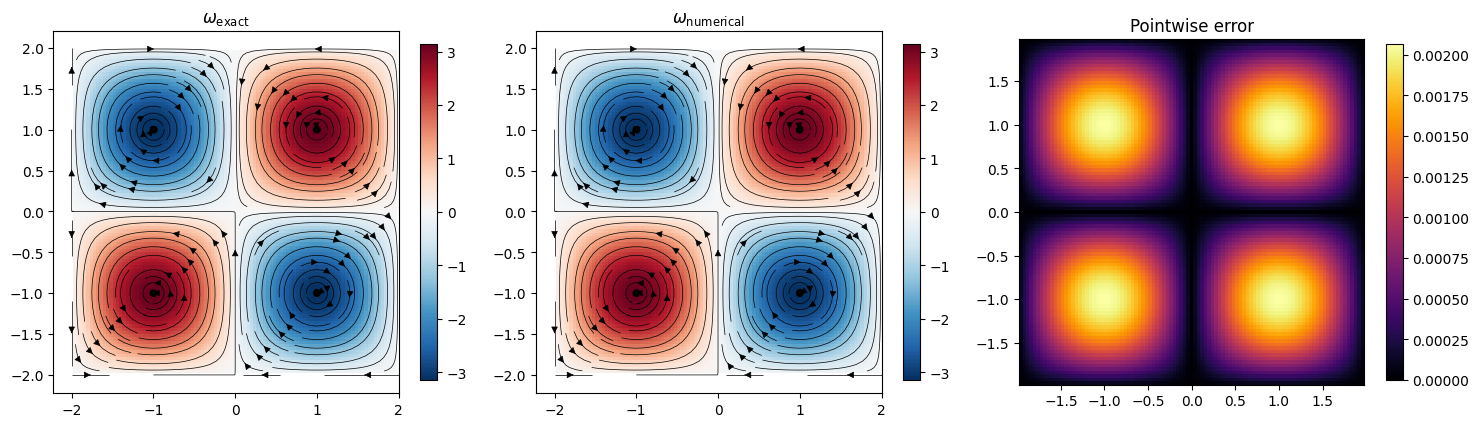

Max vorticity error: 2.0667e-03


In [8]:
omega_exact_int = omega_exact[1:-1, 1:-1]
X_int, Y_int = X[1:-1, 1:-1], Y[1:-1, 1:-1]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
vmax = np.max(np.abs(omega_exact))
im0 = axes[0].pcolormesh(X_int, Y_int, omega_exact_int, cmap='RdBu_r', vmin=-vmax, vmax=vmax, shading='auto')
axes[0].streamplot(x, y, u, v, color='k', linewidth=0.5, density=1.5)
axes[0].set_aspect('equal'); axes[0].set_title(r'$\omega_{\rm exact}$')
fig.colorbar(im0, ax=axes[0], shrink=0.8)
im1 = axes[1].pcolormesh(X_int, Y_int, omega_num, cmap='RdBu_r', vmin=-vmax, vmax=vmax, shading='auto')
axes[1].streamplot(x, y, u, v, color='k', linewidth=0.5, density=1.5)
axes[1].set_aspect('equal'); axes[1].set_title(r'$\omega_{\rm numerical}$')
fig.colorbar(im1, ax=axes[1], shrink=0.8)
err = np.abs(omega_num - omega_exact_int)
im2 = axes[2].pcolormesh(X_int, Y_int, err, cmap='inferno', shading='auto')
axes[2].set_aspect('equal'); axes[2].set_title('Pointwise error')
fig.colorbar(im2, ax=axes[2], shrink=0.8)
plt.tight_layout()
plt.show()
print(f'Max vorticity error: {np.max(err):.4e}')

**Written answer — largest vorticity error.** The absolute error is largest near the **vortex centres** $(\pm L/2,\pm L/2)$, where $|\omega_z|$ is largest. For this sinusoidal field on a uniform grid, the central-difference derivative is a constant factor $\sin(k\Delta)/(k\Delta)$ times the analytical derivative, so the local absolute error is proportional to $|\sin(\pi x/L)\sin(\pi y/L)|$. It vanishes at the saddle-type stagnation points where the analytical vorticity is zero.

## Part 3 — Temperature gradient

$$T=\sin(2\pi x/L)\cos(\pi y/L),$$
$$T_x=\frac{2\pi}{L}\cos(2\pi x/L)\cos(\pi y/L),\qquad
T_y=-\frac{\pi}{L}\sin(2\pi x/L)\sin(\pi y/L).$$

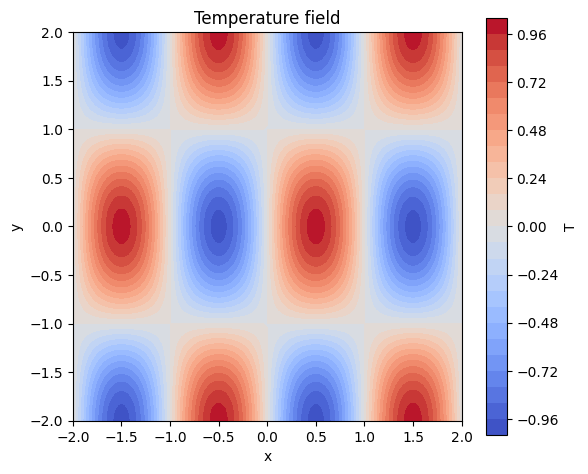

In [9]:
T = np.sin(2 * np.pi * X / L) * np.cos(np.pi * Y / L)
fig, ax = plt.subplots(figsize=(6, 5))
cf = ax.contourf(X, Y, T, levels=30, cmap='coolwarm')
fig.colorbar(cf, ax=ax, label='T')
ax.set_aspect('equal')
ax.set_title('Temperature field')
ax.set_xlabel('x'); ax.set_ylabel('y')
plt.tight_layout()
plt.show()

At the origin, $T_x(0,0)=2\pi/L>0$ and $T_y(0,0)=0$, so $\nabla T$ points in the **positive $x$ direction**.

In [10]:
dTdx_exact = (2 * np.pi / L) * np.cos(2 * np.pi * X / L) * np.cos(np.pi * Y / L)
dTdy_exact = -(np.pi / L) * np.sin(2 * np.pi * X / L) * np.sin(np.pi * Y / L)

In [11]:
dTdx_num = (T[1:-1, 2:] - T[1:-1, :-2]) / (2 * dx)
dTdy_num = (T[2:, 1:-1] - T[:-2, 1:-1]) / (2 * dy)
X_g, Y_g = X[1:-1, 1:-1], Y[1:-1, 1:-1]
T_int = T[1:-1, 1:-1]

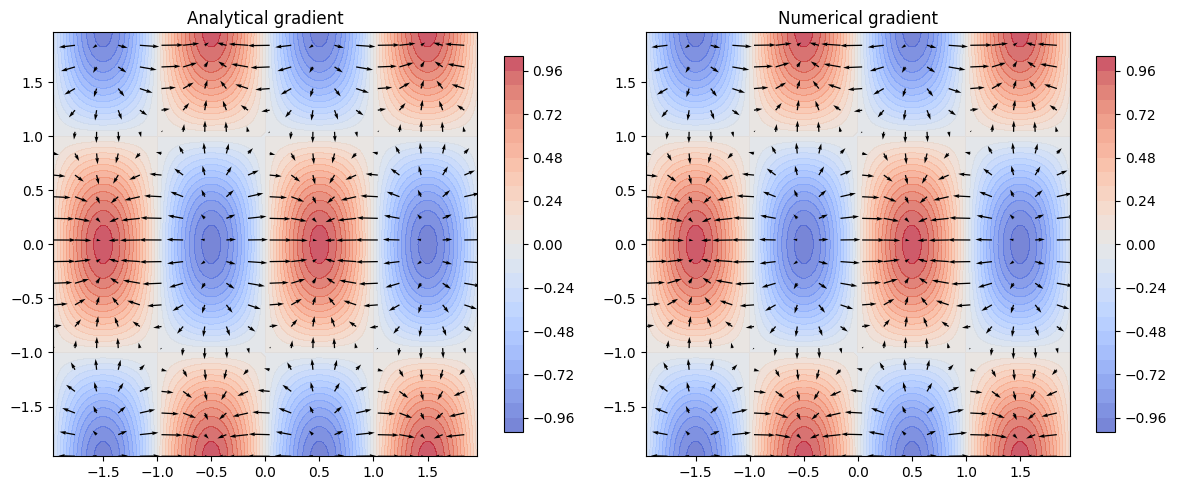

In [12]:
dTdx_exact_int = dTdx_exact[1:-1, 1:-1]
dTdy_exact_int = dTdy_exact[1:-1, 1:-1]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
s = 5
for ax, gx, gy, title in zip(axes, [dTdx_exact_int, dTdx_num], [dTdy_exact_int, dTdy_num], ['Analytical gradient', 'Numerical gradient']):
    cf = ax.contourf(X_g, Y_g, T_int, levels=30, cmap='coolwarm', alpha=0.7)
    ax.quiver(X_g[::s, ::s], Y_g[::s, ::s], gx[::s, ::s], gy[::s, ::s], color='k')
    ax.set_aspect('equal'); ax.set_title(title)
    fig.colorbar(cf, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

**Written answer — temperature maxima and Fourier's law.** At a smooth interior maximum of $T$, the temperature gradient vanishes: $\nabla T=\mathbf0$ (the gradient arrows shrink to zero). In the surrounding region, $\nabla T$ points uphill toward increasing temperature. Fourier's law $\mathbf q=-k\nabla T$, for $k>0$, makes conductive heat flux point downhill from hot to cold. The heat flux is exactly zero at the smooth maximum itself, despite heat flowing away in its neighborhood.

## Part 4 — Convergence of central-difference gradients

We measure the RMS magnitude of the vector gradient error over interior grid points: $\varepsilon=\sqrt{\mathrm{mean}[(g_{x,num}-g_{x,ex})^2+(g_{y,num}-g_{y,ex})^2]}$. This is a discrete $L_2$-type norm. (The pasted Markdown omitted the displayed error definition.)

In [13]:
Ns = [11, 21, 41, 81, 161, 321]
errors = []
for Ni in Ns:
    xi = np.linspace(-L, L, Ni)
    yi = np.linspace(-L, L, Ni)
    dxi = xi[1] - xi[0]
    dyi = yi[1] - yi[0]
    Xi, Yi = np.meshgrid(xi, yi)
    Ti = np.sin(2 * np.pi * Xi / L) * np.cos(np.pi * Yi / L)
    gx_num = (Ti[1:-1, 2:] - Ti[1:-1, :-2]) / (2 * dxi)
    gy_num = (Ti[2:, 1:-1] - Ti[:-2, 1:-1]) / (2 * dyi)
    Xc, Yc = Xi[1:-1, 1:-1], Yi[1:-1, 1:-1]
    gx_ex = (2 * np.pi / L) * np.cos(2 * np.pi * Xc / L) * np.cos(np.pi * Yc / L)
    gy_ex = -(np.pi / L) * np.sin(2 * np.pi * Xc / L) * np.sin(np.pi * Yc / L)
    err = np.sqrt(np.mean((gx_num-gx_ex)**2 + (gy_num-gy_ex)**2))
    errors.append(err)
dxs = np.array([2 * L / (Ni - 1) for Ni in Ns])
errors = np.array(errors)
assert np.all(np.diff(errors) < 0)
print(list(zip(Ns, np.round(errors, 8))))

[(11, np.float64(0.34416938)), (21, np.float64(0.09694895)), (41, np.float64(0.02526962)), (81, np.float64(0.00642224)), (161, np.float64(0.00161707)), (321, np.float64(0.0004056))]


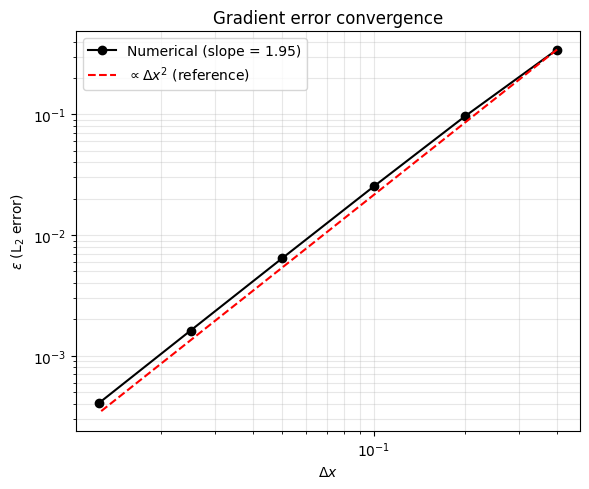

Fitted slope: 1.953 (expected: 2.0)


In [14]:
coeffs = np.polyfit(np.log10(dxs), np.log10(errors), 1)
slope = coeffs[0]
fig, ax = plt.subplots(figsize=(6, 5))
ax.loglog(dxs, errors, 'ko-', label=f'Numerical (slope = {slope:.2f})')
ax.loglog(dxs, errors[0] * (dxs / dxs[0])**2, 'r--', label=r'$\propto \Delta x^2$ (reference)')
ax.set_xlabel(r'$\Delta x$')
ax.set_ylabel(r'$\varepsilon$ (L$_2$ error)')
ax.set_title('Gradient error convergence')
ax.legend()
ax.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()
print(f'Fitted slope: {slope:.3f} (expected: 2.0)')

### Part 4c — Discussion

1. **Boundary points:** Use forward/backward one-sided differences, e.g. $(T_1-T_0)/\Delta x$ at the left boundary. The simplest one-sided formula is **first-order accurate** ($O(\Delta x)$). A three-point one-sided stencil can retain second-order accuracy.
2. **Refinement factor:** Since $\varepsilon\propto\Delta x^2$, reducing error by a factor $R$ requires reducing grid spacing by $\sqrt R$: $\Delta x_{new}=\Delta x_{old}/\sqrt R$. For example, to reduce the error by 4, halve the spacing; by 100, reduce spacing by 10. **The numeric reduction factor is absent from the supplied Markdown**, so this is the general answer.
3. **Fourth-order stencil trade-off:** A fourth-order centered derivative, $[-f_{i+2}+8f_{i+1}-8f_{i-1}+f_{i-2}]/(12\Delta x)$, has $O(\Delta x^4)$ truncation error but needs a wider stencil and special boundary treatment, introduces more inter-point communication, and can be more sensitive to insufficient smoothness or noisy data.